# Machine Learning Lab 5
## KNN Classification, Regression and EDA

**Name:** Harshit Uchasare  
**Section:** A  
**Roll No.:** 35  
**Batch:** A3  




In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     cross_val_score, StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")


#### PART A: KNN CLASSIFICATION (predict diabetes Outcome)

#### 1. Load and explore the dataset

In [2]:
df = pd.read_csv("diabetes.csv")

In [3]:
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [9]:
print(df.tail())

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
763                     0.171   63        0  
764                     0.340   27        0  
765                     0.245   30        0  
766                     0.349   47        1  
767                     0.315   23        0  


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
print(df.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [8]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


#### 2. Correlation heatmap

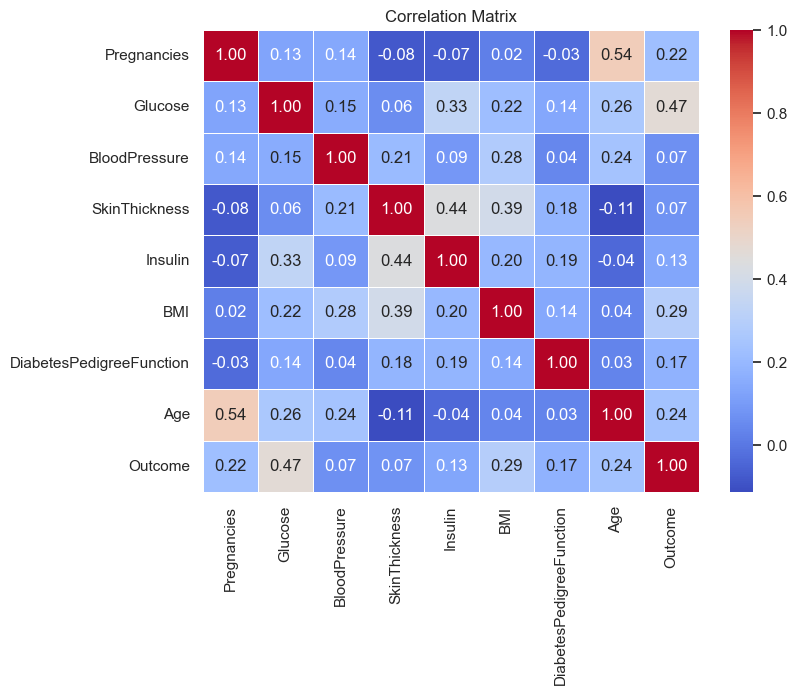

In [10]:
plt.figure(figsize=(8, 6))
correlation = df.corr()
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

#### 3. Zero values in columns where 0 is not physiologically valid

In [11]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_columns] == 0).sum()
print("Zero columns")
print(zero_counts)

Zero columns
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


#### 4. Features and target

In [12]:
df_clean = df.copy()
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]
print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (768, 8)
Y shape: (768,)


#### 5. Train/test split (80:20)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Training samples", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples 614
Testing samples: 154


In [14]:
print("Training distribution")
print(y_train.value_counts(normalize=True))
print("Testing distribution")
print(y_test.value_counts(normalize=True))

Training distribution
Outcome
0    0.653094
1    0.346906
Name: proportion, dtype: float64
Testing distribution
Outcome
0    0.642857
1    0.357143
Name: proportion, dtype: float64


#### 6. Feature scaling (fit on training data only)

In [15]:
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

#### 7. Train KNN classifier (K = 5)

In [16]:
K = 5
knn = KNeighborsClassifier(n_neighbors=K)
knn.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


#### 8. Predict

In [17]:
y_pred = knn.predict(X_test_scaled)
print("Predictions:")
print(y_pred[:20])

Predictions:
[0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 0 1 0]


#### 9. Evaluation metrics

In [23]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy:{accuracy:4f}")

Accuracy:0.694805


In [24]:
precision = precision_score(y_test, y_pred)
print(f"Precision:{precision:4f}")

Precision:0.583333


In [25]:
recall = recall_score(y_test, y_pred)
print(f"Recall:{recall:4f}")

Recall:0.509091


In [26]:
f1 = f1_score(y_test, y_pred)
print(f"F1 score:{f1:4f}")

F1 score:0.543689


In [27]:
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.75      0.80      0.77        99
    Diabetes       0.58      0.51      0.54        55

    accuracy                           0.69       154
   macro avg       0.66      0.65      0.66       154
weighted avg       0.69      0.69      0.69       154



#### 10. Confusion matrix

In [28]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[79 20]
 [27 28]]


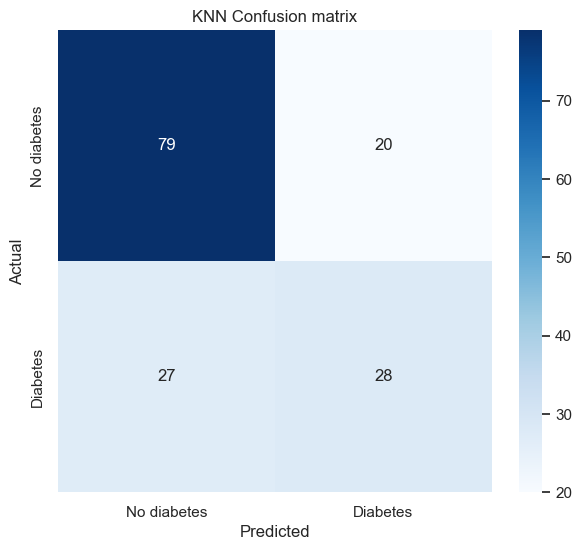

In [32]:
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No diabetes", "Diabetes"],
            yticklabels=["No diabetes", "Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion matrix")
plt.show()

#### 11. Effect of K on training and testing accuracy

In [34]:
k_values = range(1, 31)
train_accuracy = []
test_accuracy = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_accuracy.append(model.score(X_train_scaled, y_train))
    test_accuracy.append(model.score(X_test_scaled, y_test))

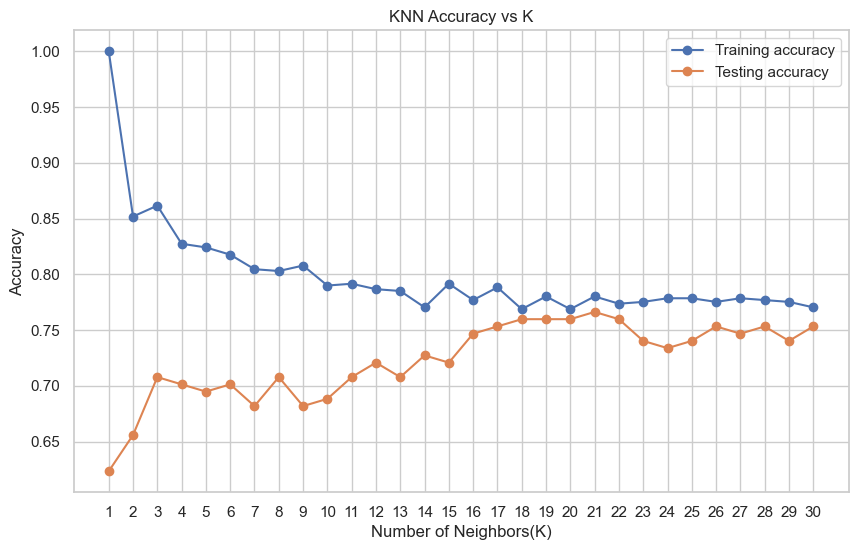

In [35]:
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_accuracy, marker="o", label="Training accuracy")
plt.plot(k_values, test_accuracy, marker="o", label="Testing accuracy")
plt.xlabel("Number of Neighbors(K)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.xticks(k_values)
plt.legend()
plt.show()

In [36]:
best_k_acccuracy = k_values[np.argmax(test_accuracy)]
best_accuracy = max(test_accuracy)
print("Best K:", best_k_acccuracy)
print("Best Accuracy:", best_accuracy)

Best K: 21
Best Accuracy: 0.7662337662337663


#### 12. Cross-validation to choose K

In [37]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = []
for k in range(1, 31):
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring="accuracy")
    cv_scores.append(scores.mean())

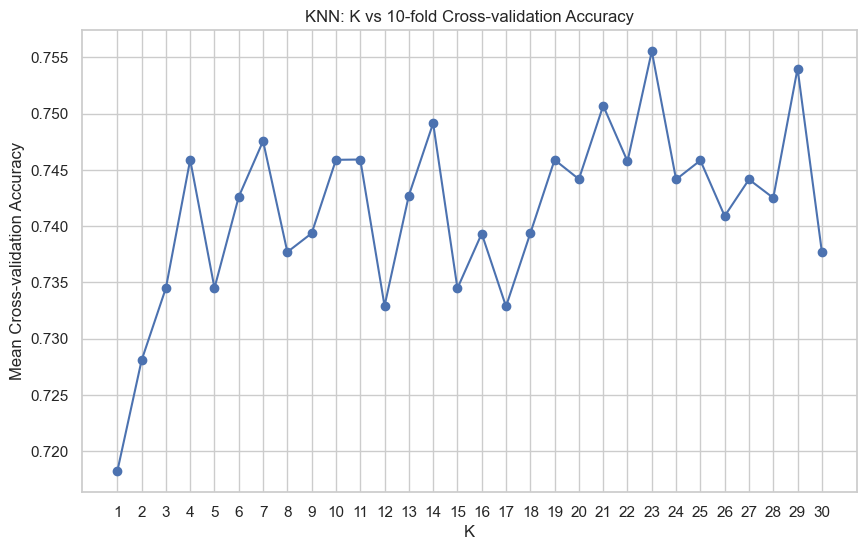

In [38]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 31), cv_scores, marker="o")
plt.xlabel("K")
plt.ylabel("Mean Cross-validation Accuracy")
plt.title("KNN: K vs 10-fold Cross-validation Accuracy")
plt.xticks(range(1, 31))
plt.show()

In [39]:
best_k_cv = np.argmax(cv_scores) + 1
print("Best K based on cross validation:", best_k_cv)
print("Best cv Accuracy:", max(cv_scores))

Best K based on cross validation: 23
Best cv Accuracy: 0.7555526176626123


#### 13. Hyper-parameter tuning with GridSearchCV

In [40]:
param_grid = {
    "n_neighbors": list(range(3, 31, 2)),
    "weights": ["uniform", "distance"],
    "metric": ["euclidian", "manhattan", "minkwoski"],
    "p": [1, 2]
}

In [41]:
grid_search = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=param_grid,
                           cv=5, scoring="accuracy", n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)
print("Grid Search completed")
print("Best parameters:")
print(grid_search.best_params_)
print("Best Cross-validation Accuracy:", grid_search.best_score_)

Grid Search completed
Best parameters:
{'metric': 'manhattan', 'n_neighbors': 13, 'p': 1, 'weights': 'distance'}
Best Cross-validation Accuracy: 0.7638677862188459


#### PART B: KNN REGRESSION (predict BMI from the other clinical features)

#### 1. Prepare data: remove rows with invalid BMI (0), median-impute other zero values

In [42]:
df_reg = df[df["BMI"] > 0].copy()
other_zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin"]
df_reg[other_zero_cols] = df_reg[other_zero_cols].replace(0, np.nan)
df_reg[other_zero_cols] = df_reg[other_zero_cols].fillna(df_reg[other_zero_cols].median())

In [43]:
Xr = df_reg.drop(columns=["BMI", "Outcome"])
yr = df_reg["BMI"]
print("Regression X shape:", Xr.shape)
print("Regression y shape:", yr.shape)

Regression X shape: (757, 7)
Regression y shape: (757,)


#### 2. Split and scale

In [44]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=42)
scaler_r = StandardScaler()
Xr_train_s = scaler_r.fit_transform(Xr_train)
Xr_test_s = scaler_r.transform(Xr_test)

#### 3. Train KNN regressor (K = 5) and predict

In [45]:
knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(Xr_train_s, yr_train)
yr_pred = knn_reg.predict(Xr_test_s)

In [46]:
comparison = pd.DataFrame({"Actual BMI": yr_test.values[:10],
                           "Predicted BMI": yr_pred[:10].round(2)})
print(comparison)

   Actual BMI  Predicted BMI
0        35.7          41.50
1        26.1          30.14
2        38.7          44.72
3        33.3          34.26
4        36.5          36.00
5        29.3          31.62
6        37.7          35.24
7        34.0          28.50
8        30.8          31.08
9        30.4          28.78


#### 4. Regression metrics

In [47]:
mae = mean_absolute_error(yr_test, yr_pred)
mse = mean_squared_error(yr_test, yr_pred)
rmse = np.sqrt(mse)
r2 = r2_score(yr_test, yr_pred)
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 4.306447368421053
MSE : 30.631213157894738
RMSE: 5.534547240551366
R2  : 0.245576569825813


#### 5. Effect of K on RMSE

In [48]:
rmse_list = []
for k in range(1, 31):
    m = KNeighborsRegressor(n_neighbors=k)
    m.fit(Xr_train_s, yr_train)
    rmse_list.append(np.sqrt(mean_squared_error(yr_test, m.predict(Xr_test_s))))

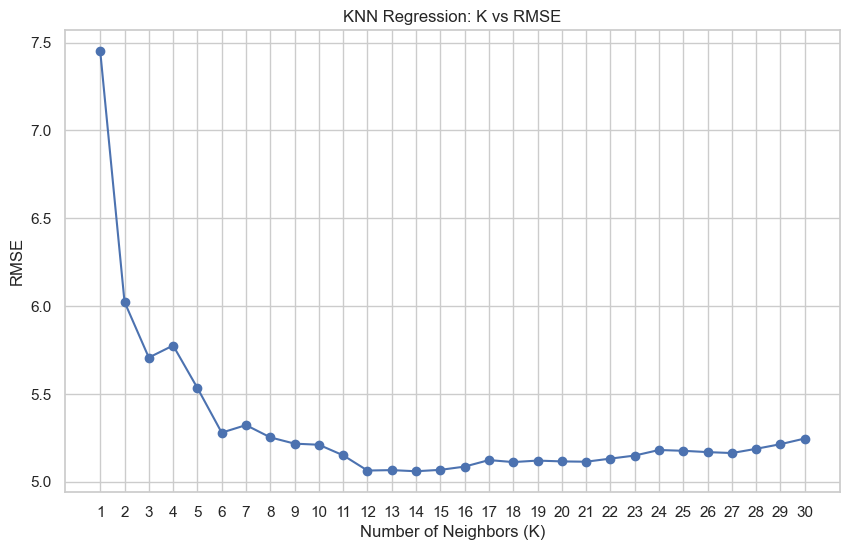

In [49]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 31), rmse_list, marker="o")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("RMSE")
plt.title("KNN Regression: K vs RMSE")
plt.xticks(range(1, 31))
plt.show()

In [50]:
best_k_reg = int(np.argmin(rmse_list)) + 1
print("Best K (lowest RMSE):", best_k_reg)
print("Lowest RMSE:", min(rmse_list))

Best K (lowest RMSE): 14
Lowest RMSE: 5.060699196362963


#### 6. Actual vs predicted plot using the best K

In [51]:
best_reg = KNeighborsRegressor(n_neighbors=best_k_reg)
best_reg.fit(Xr_train_s, yr_train)
yr_best_pred = best_reg.predict(Xr_test_s)
print("R2 with best K:", r2_score(yr_test, yr_best_pred))

R2 with best K: 0.369228564143678


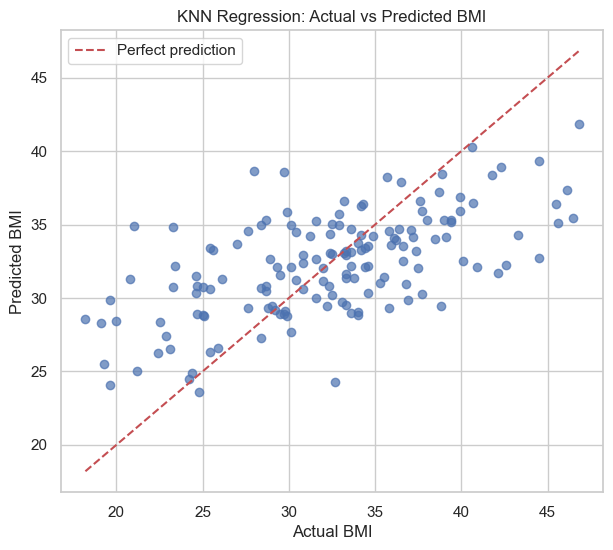

In [52]:
plt.figure(figsize=(7, 6))
plt.scatter(yr_test, yr_best_pred, alpha=0.7)
lims = [yr_test.min(), yr_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual BMI")
plt.ylabel("Predicted BMI")
plt.title("KNN Regression: Actual vs Predicted BMI")
plt.legend()
plt.show()